# Valuing a Company: DCF, Comparables and a Football Field

An equity research or M&A analyst has to answer one question: **what is this company
worth per share, and how sure are we?** This notebook values a fictional European
industrial-tech mid-cap (Helvia Industrial Tech, share price €31) with the full toolkit:

1. WACC built from CAPM, with the beta re-levered to the target capital structure
2. A 10-year free-cash-flow forecast and a DCF with a Gordon terminal value
3. Sensitivities, a Monte Carlo on the key drivers and a **reverse DCF**
4. Trading comparables and the **football field** chart used in every pitch book

The company, its peers and all figures are invented.

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("dcf.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/22-dcf-valuation")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dcf import Company, WaccInputs, forecast, dcf_value, sensitivity, reverse_dcf, monte_carlo, peers, multiples_valuation

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL, GOLD = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f", "#b08d3c"
c, w = Company(), WaccInputs()
pd.Series({"Risk-free rate": w.risk_free, "Equity risk premium": w.equity_risk_premium, "Unlevered beta": w.unlevered_beta,
           "Target D/E": w.target_debt_to_equity, "Re-levered beta": w.levered_beta, "Cost of equity": w.cost_of_equity,
           "After-tax cost of debt": w.pre_tax_cost_of_debt * (1 - w.tax_rate), "WACC": w.wacc}).to_frame("WACC build").T.round(4)

,Risk-free rate,Equity risk premium,Unlevered beta,Target D/E,Re-levered beta,Cost of equity,After-tax cost of debt,WACC
WACC build,0.03,0.055,0.95,0.35,1.1994,0.096,0.0375,0.0808


**WACC.** The beta is taken from unlevered peer betas and re-levered to Helvia's target
debt-to-equity of 35% (Hamada: $\beta_L = \beta_U(1 + (1-t)D/E)$). CAPM then gives a 9.6% cost of
equity, and the WACC is about 8.1%.

## 1. Forecast and free cash flow

Five explicit years (growth from 9% to 5%, EBIT margin from 14.5% to 16%), then five years
where growth fades to the 2% terminal rate. Free cash flow to the firm:
$\text{FCFF} = \text{EBIT}(1-t) + \text{D\&A} - \text{capex} - \Delta\text{NWC}$.

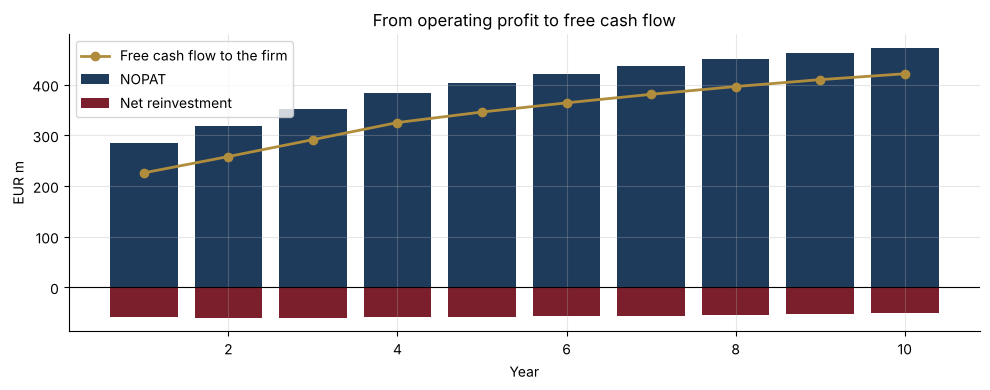

year,1,2,3,4,5,6,7,8,9,10
revenue,2616.000,2825.280,3023.050,3204.433,3364.654,3512.699,3646.182,3762.859,3860.694,3937.908
growth,0.090,0.080,0.070,0.060,0.050,0.044,0.038,0.032,0.026,0.020
EBIT,379.320,423.792,468.573,512.709,538.345,562.032,583.389,602.057,617.711,630.065
EBIT margin,0.145,0.150,0.155,0.160,0.160,0.160,0.160,0.160,0.160,0.160
FCFF,225.930,258.199,291.534,325.280,346.079,364.190,381.058,396.413,410.001,421.588


In [2]:
v = dcf_value(c, w.wacc, terminal_growth=0.02)
f = v["forecast"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(f.index, f["NOPAT"], color=NAVY, label="NOPAT")
ax.bar(f.index, -(f["capex"] - f["D&A"] + f["change in NWC"]), color=BORDEAUX, label="Net reinvestment")
ax.plot(f.index, f["FCFF"], color=GOLD, marker="o", lw=2, label="Free cash flow to the firm")
ax.axhline(0, color="black", lw=0.8); ax.set(xlabel="Year", ylabel="EUR m", title="From operating profit to free cash flow")
ax.legend(); plt.tight_layout(); plt.savefig("images/fcff.png", dpi=150); plt.show()
f[["revenue", "growth", "EBIT", "EBIT margin", "FCFF"]].T.round(3)

## 2. From enterprise value to value per share

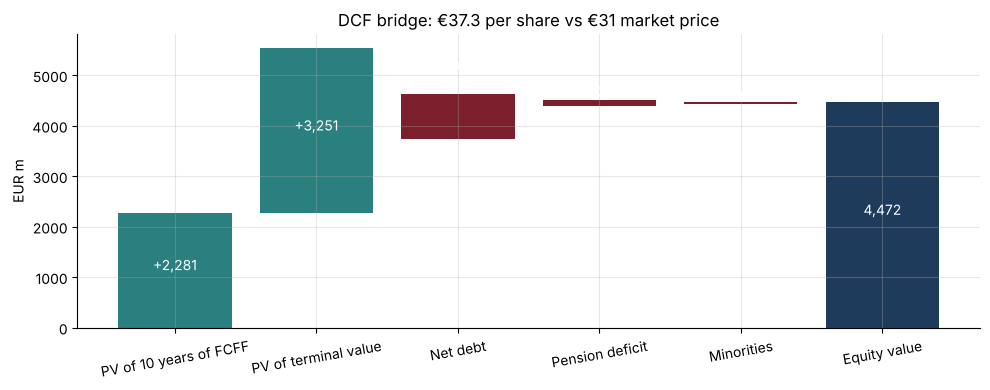

Terminal value = 59% of EV; implied exit multiple 9.0x EBITDA (peer median 9.9x)


In [3]:
steps = pd.Series({"PV of 10 years of FCFF": v["pv_fcff"], "PV of terminal value": v["pv_terminal"],
                   "Net debt": -c.net_debt, "Pension deficit": -c.pension_deficit, "Minorities": -c.minorities})
fig, ax = plt.subplots(figsize=(10, 4))
running = 0
for i, (name, val) in enumerate(steps.items()):
    ax.bar(i, val, bottom=running if val >= 0 else running + val, color=TEAL if val >= 0 else BORDEAUX)
    ax.text(i, running + val / 2, f"{val:+,.0f}", ha="center", color="white")
    running += val
ax.bar(len(steps), running, color=NAVY); ax.text(len(steps), running / 2, f"{running:,.0f}", ha="center", color="white")
ax.set_xticks(range(len(steps) + 1), [*steps.index, "Equity value"], rotation=10); ax.set_ylabel("EUR m")
ax.set_title(f"DCF bridge: €{v['per_share']:.1f} per share vs €{c.share_price:.0f} market price")
plt.tight_layout(); plt.savefig("images/dcf_bridge.png", dpi=150); plt.show()
print(f"Terminal value = {v['tv_share_of_ev']:.0%} of EV; implied exit multiple {v['implied_exit_multiple']:.1f}x EBITDA "
      f"(peer median {peers()['EV/EBITDA (NTM)'].median():.1f}x)")

Almost 60% of the value sits in the terminal value, as usual for a growing company. The
Gordon terminal value implies 9.0x year-10 EBITDA, below today's peer median of 9.9x: a useful
sanity check that the terminal assumptions are not too generous.

## 3. How sure are we?

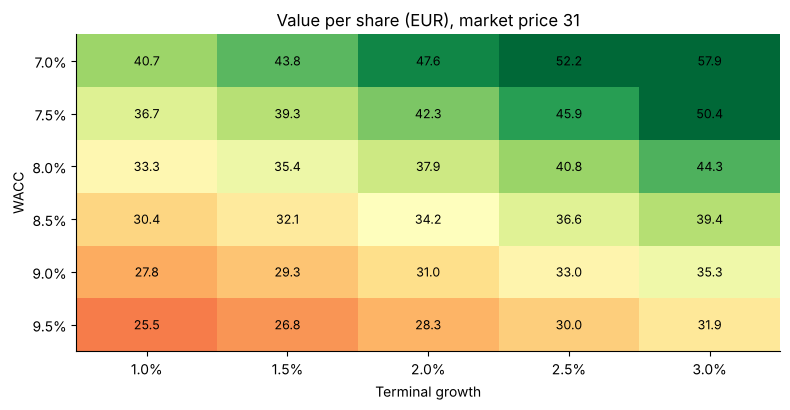

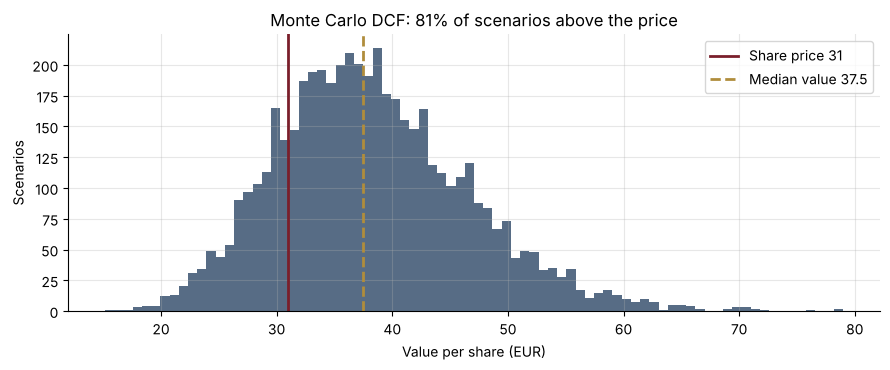

Reverse DCF: the price of 31 implies average growth of 4.1% over the next 5 years, against 7.0% in our forecast.


In [4]:
waccs = [0.070, 0.075, 0.080, 0.085, 0.090, 0.095]
growths = [0.010, 0.015, 0.020, 0.025, 0.030]
sens = sensitivity(c, waccs, growths)
fig, ax = plt.subplots(figsize=(8, 4.2))
im = ax.imshow(sens.values, cmap="RdYlGn", aspect="auto", vmin=c.share_price * 0.6, vmax=c.share_price * 1.6)
ax.set_xticks(range(len(growths)), [f"{g:.1%}" for g in growths]); ax.set_yticks(range(len(waccs)), [f"{x:.1%}" for x in waccs])
for i in range(len(waccs)):
    for j in range(len(growths)):
        ax.text(j, i, f"{sens.values[i, j]:.1f}", ha="center", va="center", fontsize=9)
ax.set(xlabel="Terminal growth", ylabel="WACC", title=f"Value per share (EUR), market price {c.share_price:.0f}"); ax.grid(False)
plt.tight_layout(); plt.savefig("images/sensitivity.png", dpi=150); plt.show()

mc = monte_carlo(c, w.wacc, n=5000)
implied_g = reverse_dcf(c, w.wacc)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(mc, bins=80, color=NAVY, alpha=0.75)
ax.axvline(c.share_price, color=BORDEAUX, lw=2, label=f"Share price {c.share_price:.0f}")
ax.axvline(np.median(mc), color=GOLD, lw=2, ls="--", label=f"Median value {np.median(mc):.1f}")
ax.set(xlabel="Value per share (EUR)", ylabel="Scenarios", title=f"Monte Carlo DCF: {(mc > c.share_price).mean():.0%} of scenarios above the price")
ax.legend(); plt.tight_layout(); plt.savefig("images/monte_carlo.png", dpi=150); plt.show()
print(f"Reverse DCF: the price of {c.share_price:.0f} implies average growth of {implied_g:.1%} over the next 5 years, "
      f"against {np.mean(c.growth):.1%} in our forecast.")

The **reverse DCF** is often the most useful output for an investment discussion: instead of
defending a point estimate, ask what the market is already pricing. Here the share price
implies about 4% growth a year, against 7% in our forecast: the debate is whether the company
can deliver its growth plan.

## 4. Trading comparables and the football field

,EV/EBITDA (NTM),EV/EBIT (NTM),P/E (NTM),EBIT margin,Revenue growth
Peer A,9.8x,13.5x,16.0x,14%,5%
Peer B,11.2x,15.0x,19.5x,17%,8%
Peer C,8.4x,11.8x,13.2x,11%,3%
Peer D,12.5x,17.2x,22.0x,19%,10%
Peer E,10.1x,13.9x,17.1x,15%,6%
Peer F,9.2x,12.6x,15.4x,13%,4%


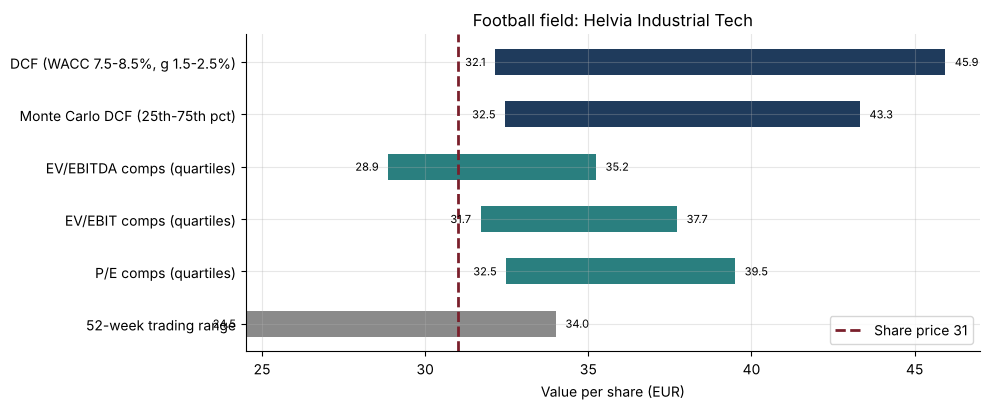

In [5]:
pr = peers()
ntm = f.iloc[0]
ebitda_ntm = ntm["EBIT"] + ntm["D&A"]
net_income_ntm = (ntm["EBIT"] - 0.05 * c.net_debt) * (1 - c.tax_rate)
comps = {k: multiples_valuation(c, pr.quantile(q), ebitda_ntm, ntm["EBIT"], net_income_ntm) for k, q in [("low", 0.25), ("mid", 0.5), ("high", 0.75)]}
display(pr.style.format({"EV/EBITDA (NTM)": "{:.1f}x", "EV/EBIT (NTM)": "{:.1f}x", "P/E (NTM)": "{:.1f}x",
                         "EBIT margin": "{:.0%}", "Revenue growth": "{:.0%}"}))

ranges = {"DCF (WACC 7.5-8.5%, g 1.5-2.5%)": (sens.loc[0.085, 0.015], sens.loc[0.075, 0.025]),
          "Monte Carlo DCF (25th-75th pct)": tuple(np.percentile(mc, [25, 75])),
          "EV/EBITDA comps (quartiles)": (comps["low"]["EV/EBITDA"], comps["high"]["EV/EBITDA"]),
          "EV/EBIT comps (quartiles)": (comps["low"]["EV/EBIT"], comps["high"]["EV/EBIT"]),
          "P/E comps (quartiles)": (comps["low"]["P/E"], comps["high"]["P/E"]),
          "52-week trading range": (24.5, 34.0)}
fig, ax = plt.subplots(figsize=(10, 4.2))
for i, (name, (lo, hi)) in enumerate(ranges.items()):
    ax.barh(i, hi - lo, left=lo, color=[NAVY, NAVY, TEAL, TEAL, TEAL, GREY][i], height=0.5)
    ax.text(lo - 0.3, i, f"{lo:.1f}", va="center", ha="right", fontsize=8); ax.text(hi + 0.3, i, f"{hi:.1f}", va="center", fontsize=8)
ax.axvline(c.share_price, color=BORDEAUX, lw=2, ls="--", label=f"Share price {c.share_price:.0f}")
ax.set_yticks(range(len(ranges)), list(ranges)); ax.invert_yaxis(); ax.set_xlabel("Value per share (EUR)")
ax.set_title("Football field: Helvia Industrial Tech"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("images/football_field.png", dpi=150); plt.show()

**Reading the football field.** The intrinsic methods (DCF, Monte Carlo) sit mostly above
the price, from about €32 to €46. The peer multiples give a lower range, from €29 to €40, with
EV/EBITDA bracketing today's price. Where the bars overlap, around €32 to €38, is the
defensible fair-value range. The gap between the two families is the growth the market does
not yet believe in, which is what the reverse DCF measured.

## Conclusions
- A DCF value of about €37 per share against €31, but 59% of the value is in the terminal value.
- The Monte Carlo puts about 80% of scenarios above the price; the reverse DCF shows that the
  market prices roughly 4% growth against 7% in the plan.
- Comparables give a lower range (€29 to €40): the investment case rests on delivering growth.
- **Next steps:** a three-statement model, an APV valuation for a changing capital structure,
  precedent transactions with control premia, and sum-of-the-parts for a conglomerate.